# B-Spline Linear Hash Encoding Single-Run Experiment — Matched to Instant-NGP

This notebook trains the hashed linear B-spline NeRF once using the same hyperparameters, hash function, encoder dimensions, MLP architecture, rendering settings, output layout, and metrics as the Instant-NGP single-run notebook.


In [ ]:
# Optional: mount Google Drive when running on Colab.
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
except Exception as e:
    print("Drive mount skipped or already mounted:", e)


Mounted at /content/drive


In [ ]:
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import numpy as np
import os
import imageio
import torch.nn as nn
from tqdm import tqdm

import json, csv, time, random, platform, shutil
from datetime import datetime


In [ ]:
#Check GPU
import torch

print(torch.cuda.is_available())
print(torch.cuda.device_count())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
1
NVIDIA A100-SXM4-40GB


In [ ]:
def get_rays(datapath, mode='train'):

    pose_file_names = [f for f in os.listdir(datapath + f'/{mode}/pose') if f.endswith('.txt')]
    intrisics_file_names = [f for f in os.listdir(datapath + f'/{mode}/intrinsics') if f.endswith('.txt')]
    img_file_names = [f for f in os.listdir(datapath + '/imgs') if mode in f]

    assert len(pose_file_names) == len(intrisics_file_names)
    assert len(img_file_names) == len(pose_file_names)

    # Read
    N = len(pose_file_names)
    poses = np.zeros((N, 4, 4))
    intrinsics = np.zeros((N, 4, 4))

    images = []

    for i in range(N):
        name = pose_file_names[i]

        pose = open(datapath + f'/{mode}/pose/' + name).read().split()
        poses[i] = np.array(pose, dtype=float).reshape(4, 4)

        intrinsic = open(datapath + f'/{mode}/intrinsics/' + name).read().split()
        intrinsics[i] = np.array(intrinsic, dtype=float).reshape(4, 4)

        # Read images
        img = imageio.imread(datapath + '/imgs/' + name.replace('txt', 'png')) / 255.
        images.append(img[None, ...])
    images = np.concatenate(images)

    H = images.shape[1]
    W = images.shape[2]

    if images.shape[3] == 4: #RGBA -> RGB
        images = images[..., :3] * images[..., -1:] + (1 - images[..., -1:])

    rays_o = np.zeros((N, H*W, 3))
    rays_d = np.zeros((N, H*W, 3))
    target_px_values = images.reshape((N, H*W, 3))

    for i in range(N):

        c2w = poses[i]
        f = intrinsics[i, 0, 0]

        u = np.arange(W)
        v = np.arange(H)
        u, v = np.meshgrid(u, v)
        dirs = np.stack((u - W / 2, -(v - H / 2), - np.ones_like(u) * f), axis=-1)
        dirs = (c2w[:3, :3] @ dirs[..., None]).squeeze(-1)
        dirs = dirs / np.linalg.norm(dirs, axis=-1, keepdims=True)

        rays_d[i] = dirs.reshape(-1, 3)
        rays_o[i] += c2w[:3, 3]

    return rays_o, rays_d, target_px_values

In [ ]:
def bspline_basis_linear(u):
    """
    Degree-1 B-spline basis on the unit cell.

    For u in [0, 1]:
        B_0(u) = 1 - u
        B_1(u) = u

    These are exactly the same weights used in trilinear interpolation.
    """
    w0 = 1.0 - u
    w1 = u
    return torch.stack([w0, w1], dim=-1)


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class HashedLinearBSplineField(nn.Module):
    """
    Linear B-spline version of the Instant-NGP hash-grid encoder.

    This is intentionally matched to the Instant_NGP_single_run notebook:
        - same number of levels
        - same feature dimension
        - same hash table size
        - same base resolution
        - same per-level scale
        - same hash function
        - same table initialization
        - same trilinear / degree-1 B-spline weights

    Mathematical interpretation:
        trilinear interpolation = tensor-product degree-1 B-spline interpolation.
    """

    def __init__(
        self,
        n_levels=12,
        feat_dim=2,
        log2_hashmap_size=15,
        base_res=16,
        per_level_scale=2.0,
    ):
        super().__init__()

        self.n_levels = n_levels
        self.feat_dim = feat_dim
        self.hashmap_size = 2 ** log2_hashmap_size
        self.base_res = base_res
        self.base_resolution = base_res  # alias for logging compatibility
        self.per_level_scale = per_level_scale

        # Same learned hash tables as Instant-NGP notebook.
        self.tables = nn.ParameterList([
            nn.Parameter(torch.randn(self.hashmap_size, feat_dim) * 0.01)
            for _ in range(n_levels)
        ])

        # Same primes and same sum-based hash as the Instant-NGP notebook.
        self.register_buffer(
            "primes",
            torch.tensor([1, 2654435761, 805459861], dtype=torch.long)
        )

        offsets = [[i, j, k] for i in [0, 1] for j in [0, 1] for k in [0, 1]]
        self.register_buffer("offsets", torch.tensor(offsets, dtype=torch.long))

    def hash(self, idx):
        """
        idx: [..., 3] integer lattice coordinates.
        Returns hashed table indices in [0, hashmap_size).
        """
        if idx.dtype != torch.long:
            idx = idx.long()
        x = (idx * self.primes.to(idx.device)).sum(dim=-1)
        return x % self.hashmap_size

    def forward(self, xyz):
        """
        xyz: [B, 3], expected in [0, 1], exactly as in the Instant-NGP notebook's renderer.
        """
        feats = []

        for lvl in range(self.n_levels):
            res = int(self.base_res * (self.per_level_scale ** lvl))

            # Continuous lattice coordinate.
            pos = xyz * res
            idx0 = torch.floor(pos).long()
            u = pos - idx0.float()

            # 8 corners of the linear B-spline / trilinear stencil.
            corners = idx0[:, None, :] + self.offsets[None, :, :]

            h = self.hash(corners.reshape(-1, 3))
            corner_feats = self.tables[lvl][h].view(xyz.shape[0], 8, self.feat_dim)

            # Degree-1 tensor-product B-spline weights.
            # This ordering exactly matches the Instant-NGP notebook:
            # [000, 001, 010, 011, 100, 101, 110, 111]
            wx, wy, wz = u[:, 0], u[:, 1], u[:, 2]
            weights = torch.stack([
                (1 - wx) * (1 - wy) * (1 - wz),
                (1 - wx) * (1 - wy) * wz,
                (1 - wx) * wy * (1 - wz),
                (1 - wx) * wy * wz,
                wx * (1 - wy) * (1 - wz),
                wx * (1 - wy) * wz,
                wx * wy * (1 - wz),
                wx * wy * wz,
            ], dim=1).unsqueeze(-1)

            feat = (corner_feats * weights).sum(dim=1)
            feats.append(feat)

        return torch.cat(feats, dim=-1)


In [ ]:
class NerfSpline(nn.Module):
    """
    Linear B-spline NeRF matched to the Instant-NGP single-run architecture.

    The only conceptual difference is the name/interpretation of the encoder:
    the encoder performs degree-1 tensor-product B-spline interpolation, which is
    algebraically identical to trilinear interpolation.
    """

    def __init__(
        self,
        hidden_dim=128,
        n_levels=12,
        feat_per_level=2,
        log2_hashmap_size=15,
        base_resolution=16,
        per_level_scale=2.0,
    ):
        super().__init__()

        self.encoder = HashedLinearBSplineField(
            n_levels=n_levels,
            feat_dim=feat_per_level,
            log2_hashmap_size=log2_hashmap_size,
            base_res=base_resolution,
            per_level_scale=per_level_scale,
        )

        enc_out_dim = self.encoder.n_levels * self.encoder.feat_dim

        # Same MLP structure as NerfInstantNGP.
        self.trunk = nn.Sequential(
            nn.Linear(enc_out_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU()
        )

        self.sigma_head = nn.Linear(hidden_dim, 1)
        self.feature_head = nn.Linear(hidden_dim, hidden_dim)

        self.color_mlp = nn.Sequential(
            nn.Linear(hidden_dim + 3, hidden_dim // 2),
            nn.ReLU(),
            nn.Linear(hidden_dim // 2, 3),
            nn.Sigmoid()
        )

    def forward(self, xyz, d):
        enc = self.encoder(xyz)
        h = self.trunk(enc)

        # Same density activation as Instant-NGP notebook.
        sigma = F.softplus(self.sigma_head(h)).squeeze(-1)

        feat = self.feature_head(h)
        rgb = self.color_mlp(torch.cat([feat, d], dim=-1))

        return rgb, sigma

    def intersect(self, x, d):
        return self.forward(x, d)


In [ ]:
# The old unmatched NerfSpline definition has been replaced above.
# From this point onward, NerfSpline uses the same architecture and hyperparameters as Instant-NGP,
# while interpreting the interpolation as degree-1 tensor-product B-splines.


In [ ]:
def training(model, optimizer, scheduler, tn, tf, nb_bins, nb_epochs, data_loader, device='cpu'):

    training_loss = []
    psnr = []
    for epoch in (range(nb_epochs)):
        for batch in tqdm(data_loader):
            o = batch[:, :3].to(device)
            d = batch[:, 3:6].to(device)

            target = batch[:, 6:].to(device)

            prediction = rendering(model, o, d, tn, tf, nb_bins=nb_bins, device=device)

            loss = ((prediction - target)**2).mean()

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            training_loss.append(loss.item())
            psnr.append(20 * np.log10(1.0 / np.sqrt(loss.item())))

        scheduler.step()

        torch.save(model.cpu(), 'model_nerf')
        model.to(device)

    return training_loss, psnr

In [ ]:
def compute_accumulated_transmittance(betas):
    accumulated_transmittance = torch.cumprod(betas, 1)
    return torch.cat((torch.ones(accumulated_transmittance.shape[0], 1, device=accumulated_transmittance.device),
                      accumulated_transmittance[:, :-1]), dim=1)

In [ ]:
def rendering(model, rays_o, rays_d, tn, tf, nb_bins=100, device='cpu', white_bckgr=True):

    # ---- cache t_vals + delta so they are not recomputed every batch ----
    if not hasattr(rendering, "cache"):
        rendering.cache = {}

    key = (tn, tf, nb_bins, device)

    if key not in rendering.cache:
        t_vals = torch.linspace(tn, tf, nb_bins, device=device)
        delta = torch.cat(
            (t_vals[1:] - t_vals[:-1],
             torch.tensor([1e10], device=device))
        )
        rendering.cache[key] = (t_vals, delta)

    t_vals, delta = rendering.cache[key]
    # ---------------------------------------------------------------------

    rays_d = rays_d / (torch.norm(rays_d, dim=-1, keepdim=True) + 1e-9)

    x = rays_o.unsqueeze(1) + \
        t_vals.unsqueeze(0).unsqueeze(-1) * rays_d.unsqueeze(1)

    x = (x / tf) * 0.5 + 0.5

    colors, density = model.intersect(
        x.reshape(-1, 3),
        rays_d.expand(x.shape[1], x.shape[0], 3)
              .transpose(0, 1)
              .reshape(-1, 3)
    )

    colors = colors.reshape((x.shape[0], nb_bins, 3))
    density = density.reshape((x.shape[0], nb_bins))

    alpha = 1 - torch.exp(-density * delta.unsqueeze(0))

    weights = compute_accumulated_transmittance(1 - alpha) * alpha

    c = (weights.unsqueeze(-1) * colors).sum(1)

    if white_bckgr:
        weight_sum = weights.sum(-1)
        return c + 1 - weight_sum.unsqueeze(-1)
    else:
        return c

In [ ]:
def psnr_from_mse(mse: float, max_val: float = 1.0) -> float:
    mse = max(mse, 1e-12)
    return 20.0 * np.log10(max_val / np.sqrt(mse))

def save_checkpoint(path, model, optimizer, scheduler, epoch, *, tn, tf, nb_bins, extra=None):
    ckpt = {
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optim_state": optimizer.state_dict() if optimizer is not None else None,
        "sched_state": scheduler.state_dict() if scheduler is not None else None,
        "params": {"tn": tn, "tf": tf, "nb_bins": nb_bins},
        "extra": extra or {},
    }
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    torch.save(ckpt, path)

def load_checkpoint(path, model, optimizer=None, scheduler=None, map_location="cpu"):
    ckpt = torch.load(path, map_location=map_location)
    model.load_state_dict(ckpt["model_state"])
    if optimizer is not None and ckpt.get("optim_state") is not None:
        optimizer.load_state_dict(ckpt["optim_state"])
    if scheduler is not None and ckpt.get("sched_state") is not None:
        scheduler.load_state_dict(ckpt["sched_state"])
    return ckpt  # contains epoch + params too

def train_single_epoch(
    model,
    optimizer,
    scheduler,
    tn,
    tf,
    nb_bins,
    data_loader,
    *,
    device="cpu",
    epoch_idx=0,
    ckpt_dir="checkpoints",
    ckpt_name_prefix="nerf",
    save_every_epoch=True,
):
    model.train()
    model.to(device)

    epoch_losses = []
    epoch_psnr = []

    for batch in tqdm(data_loader, desc=f"epoch {epoch_idx}"):
        batch = batch.to(device)  # assumes batch is a tensor
        o = batch[:, :3]
        d = batch[:, 3:6]
        target = batch[:, 6:]

        prediction = rendering(model, o, d, tn, tf, nb_bins=nb_bins, device=device)
        loss = ((prediction - target) ** 2).mean()

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        mse = float(loss.detach().item())
        epoch_losses.append(mse)
        epoch_psnr.append(psnr_from_mse(mse))

    if scheduler is not None:
        scheduler.step()

    if save_every_epoch:
        ckpt_path = os.path.join(
            ckpt_dir,
            f"{ckpt_name_prefix}_epoch{epoch_idx:04d}_tn{tn}_tf{tf}_bins{nb_bins}.pt",
        )
        save_checkpoint(
            ckpt_path,
            model,
            optimizer,
            scheduler,
            epoch_idx,
            tn=tn,
            tf=tf,
            nb_bins=nb_bins,
            extra={"mean_loss": float(np.mean(epoch_losses))},
        )

    return epoch_losses, epoch_psnr

## Single-run configuration


In [ ]:
# -----------------------------
# Single run configuration
# -----------------------------
SEED = 42

# Dataset path
DATASET_PATH = ""

# Output path: this run folder will contain images, checkpoints, logs, plots, and metadata.
EXPERIMENT_ROOT = "/content/drive/MyDrive/Thesis/Papers Implemented/experiments"
RUN_NAME = "bspline_linear_hashed_single_run"

# Training parameters
BATCH_SIZE = 1024
NB_EPOCHS = 10
LR = 1e-4
GAMMA = 0.5
MILESTONES = [5, 10]
TN = 8.0
TF = 12.0
NB_BINS = 100

# Image/render parameters
H = 400
W = 400
TEST_IMAGE_INDEX = 0
RENDER_CHUNK_SIZE = 4096   # rays per render chunk; lower this if you get CUDA OOM

# Model parameters
HIDDEN_DIM = 128
N_LEVELS = 12
FEAT_PER_LEVEL = 2
LOG2_HASHMAP_SIZE = 15
BASE_RESOLUTION = 16
TABLE_SIZE = 2**LOG2_HASHMAP_SIZE
PER_LEVEL_SCALE = 2.0

# Safety/performance switches
SAVE_CHECKPOINT_EVERY_EPOCH = True
SAVE_FINAL_MODEL_STATE = True

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_DIR = os.path.join(EXPERIMENT_ROOT, f"{RUN_NAME}_{timestamp}")
IMG_DIR = os.path.join(RUN_DIR, "epoch_images")
CKPT_DIR = os.path.join(RUN_DIR, "checkpoints")
PLOT_DIR = os.path.join(RUN_DIR, "plots")

for d in [RUN_DIR, IMG_DIR, CKPT_DIR, PLOT_DIR]:
    os.makedirs(d, exist_ok=True)

config = {
    "method": "Hashed linear B-spline multiresolution encoding matched to Instant-NGP",
    "run_name": RUN_NAME,
    "timestamp": timestamp,
    "seed": SEED,
    "dataset_path": DATASET_PATH,
    "batch_size": BATCH_SIZE,
    "nb_epochs": NB_EPOCHS,
    "learning_rate": LR,
    "scheduler": {"type": "MultiStepLR", "milestones": MILESTONES, "gamma": GAMMA},
    "tn": TN,
    "tf": TF,
    "nb_bins": NB_BINS,
    "image_height": H,
    "image_width": W,
    "test_image_index": TEST_IMAGE_INDEX,
    "render_chunk_size": RENDER_CHUNK_SIZE,
    "hidden_dim": HIDDEN_DIM,
    "n_levels": N_LEVELS,
    "feat_per_level": FEAT_PER_LEVEL,
    "base_resolution": BASE_RESOLUTION,
    "log2_hashmap_size": LOG2_HASHMAP_SIZE,
    "table_size": TABLE_SIZE,
    "per_level_scale": PER_LEVEL_SCALE,
    "device": device,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "python": platform.python_version(),
    "torch": torch.__version__,
}

with open(os.path.join(RUN_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=2)

print("Run directory:", RUN_DIR)


Device: cuda
GPU: NVIDIA A100-SXM4-40GB
Run directory: /content/drive/MyDrive/Thesis/Papers Implemented/experiments/bspline_linear_hashed_single_run_20260603_090808


In [ ]:
# -----------------------------
# Load train/test rays
# -----------------------------
o, d, target_px_values = get_rays(DATASET_PATH, mode="train")

train_tensor = torch.cat((
    torch.from_numpy(o).reshape(-1, 3).float(),
    torch.from_numpy(d).reshape(-1, 3).float(),
    torch.from_numpy(target_px_values).reshape(-1, 3).float()
), dim=1)

dataloader = DataLoader(
    train_tensor,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device == "cuda"),
)

test_o, test_d, test_target_px_values = get_rays(DATASET_PATH, mode="test")

dataset_summary = {
    "train_images": int(o.shape[0]),
    "test_images": int(test_o.shape[0]),
    "height": H,
    "width": W,
    "train_rays": int(train_tensor.shape[0]),
    "train_batches_per_epoch": int(len(dataloader)),
}

with open(os.path.join(RUN_DIR, "dataset_summary.json"), "w") as f:
    json.dump(dataset_summary, f, indent=2)

print(dataset_summary)


/tmp/ipykernel_1987/3129188668.py:27: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread(datapath + '/imgs/' + name.replace('txt', 'png')) / 255.


{'train_images': 90, 'test_images': 10, 'height': 400, 'width': 400, 'train_rays': 14400000, 'train_batches_per_epoch': 14063}


In [ ]:
# -----------------------------
# Extra helpers for logging
# -----------------------------
def count_parameters(model):
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))

def save_json(path, data):
    with open(path, "w") as f:
        json.dump(data, f, indent=2)

def append_jsonl(path, item):
    with open(path, "a") as f:
        f.write(json.dumps(item) + "\n")

def write_metrics_csv(path, rows):
    if not rows:
        return
    fieldnames = list(rows[0].keys())
    with open(path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

def mse2psnr(mse: float, max_val: float = 1.0) -> float:
    mse = max(float(mse), 1e-12)
    return 20.0 * np.log10(max_val / np.sqrt(mse))

@torch.no_grad()
def render_image_from_rays_chunked(
    model,
    o_np,
    d_np,
    *,
    tn: float,
    tf: float,
    nb_bins: int,
    chunk_size: int,
    H: int,
    W: int,
    target_np=None,
    device: str = "cuda",
):
    """Renders one full image from rays. Here chunk_size means rays per chunk."""
    model.to(device)
    model.eval()

    o_t = torch.from_numpy(o_np).float()
    d_t = torch.from_numpy(d_np).float()

    rgb_chunks = []
    for start in tqdm(range(0, o_t.shape[0], chunk_size), desc="render", leave=False):
        end = min(start + chunk_size, o_t.shape[0])
        o_b = o_t[start:end].to(device)
        d_b = d_t[start:end].to(device)
        rgb_b = rendering(model, o_b, d_b, tn, tf, nb_bins=nb_bins, device=device)
        rgb_chunks.append(rgb_b.detach().cpu())

    image_np = torch.cat(rgb_chunks, dim=0).reshape(H, W, 3).numpy()
    image_np = np.clip(image_np, 0.0, 1.0)

    mse = psnr = None
    if target_np is not None:
        tgt = np.asarray(target_np)
        if tgt.ndim == 2 and tgt.shape[-1] == 3:
            tgt = tgt.reshape(H, W, 3)
        mse = float(((image_np - tgt) ** 2).mean())
        psnr = float(mse2psnr(mse))

    return image_np, mse, psnr

def save_epoch_image(image_np, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    imageio.imwrite(path, (np.clip(image_np, 0.0, 1.0) * 255).astype(np.uint8))

def save_metric_plots(rows):
    epochs = [r["epoch"] for r in rows]

    plt.figure()
    plt.plot(epochs, [r["train_mean_psnr"] for r in rows], marker="o", label="train mean PSNR")
    plt.plot(epochs, [r["test_psnr"] for r in rows], marker="o", label="test PSNR")
    plt.xlabel("Epoch")
    plt.ylabel("PSNR (dB)")
    plt.legend()
    plt.grid(True)
    plt.savefig(os.path.join(PLOT_DIR, "psnr_by_epoch.png"), dpi=200, bbox_inches="tight")
    plt.show()

    plt.figure()
    plt.plot(epochs, [r["train_mean_loss"] for r in rows], marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Mean training MSE")
    plt.grid(True)
    plt.savefig(os.path.join(PLOT_DIR, "loss_by_epoch.png"), dpi=200, bbox_inches="tight")
    plt.show()


{'class': 'NerfSpline', 'trainable_parameters': 831428, 'encoder_class': 'HashedLinearBSplineField', 'encoder_n_levels': 12, 'encoder_feat_dim': 2, 'encoder_hashmap_size': 32768, 'encoder_base_res': 16, 'encoder_base_resolution': 16, 'encoder_per_level_scale': 2.0}


epoch 0: 100%|██████████| 14063/14063 [10:02<00:00, 23.35it/s]


Epoch 0000 | train PSNR 25.99 dB | test PSNR 29.50 dB | image saved: epoch_0000_test0_psnr_29.50.png


epoch 1: 100%|██████████| 14063/14063 [10:01<00:00, 23.39it/s]


Epoch 0001 | train PSNR 29.90 dB | test PSNR 30.62 dB | image saved: epoch_0001_test0_psnr_30.62.png


epoch 2: 100%|██████████| 14063/14063 [10:02<00:00, 23.36it/s]


... (11 outputs left out)

epoch 8: 100%|██████████| 14063/14063 [09:49<00:00, 23.84it/s]


Epoch 0008 | train PSNR 32.49 dB | test PSNR 30.59 dB | image saved: epoch_0008_test0_psnr_30.59.png


epoch 9: 100%|██████████| 14063/14063 [09:55<00:00, 23.60it/s]


Epoch 0009 | train PSNR 32.61 dB | test PSNR 30.48 dB | image saved: epoch_0009_test0_psnr_30.48.png


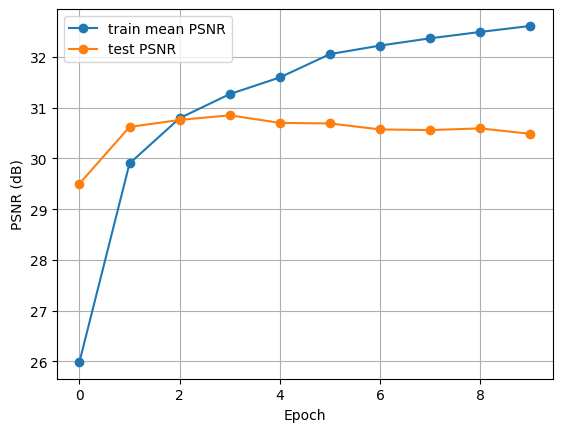

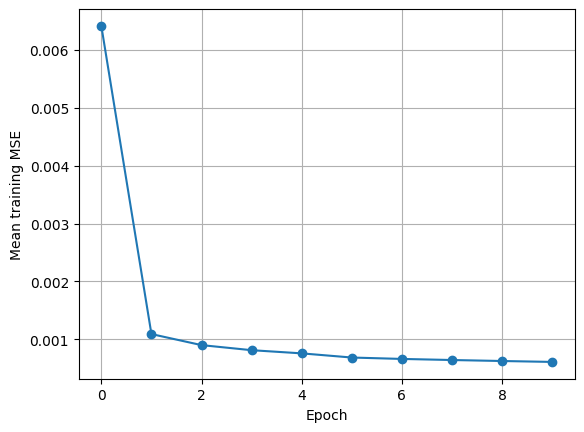

Run complete.
Best test PSNR: 30.848293553850713 at epoch 3
Chapter 4 summary: /content/drive/MyDrive/Thesis/Papers Implemented/experiments/bspline_linear_hashed_single_run_20260603_090808/chapter4_summary.json


In [ ]:
# -----------------------------
# Single complete run
# -----------------------------
model = NerfSpline(
    hidden_dim=HIDDEN_DIM,
    n_levels=N_LEVELS,
    feat_per_level=FEAT_PER_LEVEL,
    log2_hashmap_size=LOG2_HASHMAP_SIZE,
    base_resolution=BASE_RESOLUTION,
    per_level_scale=PER_LEVEL_SCALE,
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=MILESTONES, gamma=GAMMA)

model_summary = {
    "class": model.__class__.__name__,
    "trainable_parameters": count_parameters(model),
    "encoder_class": model.encoder.__class__.__name__,
    "encoder_n_levels": int(model.encoder.n_levels),
    "encoder_feat_dim": int(model.encoder.feat_dim),
    "encoder_hashmap_size": int(model.encoder.hashmap_size),
    "encoder_base_res": int(model.encoder.base_res),
    "encoder_base_resolution": int(model.encoder.base_resolution),
    "encoder_per_level_scale": float(model.encoder.per_level_scale),
}
save_json(os.path.join(RUN_DIR, "model_summary.json"), model_summary)
print(model_summary)

all_rows = []
all_batch_losses = []
all_batch_psnr = []

metrics_jsonl_path = os.path.join(RUN_DIR, "epoch_metrics.jsonl")

run_start = time.time()

for epoch in range(NB_EPOCHS):
    epoch_start = time.time()

    epoch_losses, epoch_psnr = train_single_epoch(
        model,
        optimizer,
        scheduler,
        TN,
        TF,
        NB_BINS,
        dataloader,
        device=device,
        epoch_idx=epoch,
        ckpt_dir=CKPT_DIR,
        ckpt_name_prefix="bspline_linear_hashed",
        save_every_epoch=SAVE_CHECKPOINT_EVERY_EPOCH,
    )

    # Render the same held-out test image at the end of every epoch.
    image_np, test_mse, test_psnr = render_image_from_rays_chunked(
        model,
        test_o[TEST_IMAGE_INDEX],
        test_d[TEST_IMAGE_INDEX],
        tn=TN,
        tf=TF,
        nb_bins=NB_BINS,
        chunk_size=RENDER_CHUNK_SIZE,
        H=H,
        W=W,
        target_np=test_target_px_values[TEST_IMAGE_INDEX],
        device=device,
    )

    image_path = os.path.join(IMG_DIR, f"epoch_{epoch:04d}_test{TEST_IMAGE_INDEX}_psnr_{test_psnr:.2f}.png")
    save_epoch_image(image_np, image_path)

    row = {
        "epoch": int(epoch),
        "train_mean_loss": float(np.mean(epoch_losses)),
        "train_mean_psnr": float(np.mean(epoch_psnr)),
        "train_last_loss": float(epoch_losses[-1]),
        "train_last_psnr": float(epoch_psnr[-1]),
        "test_mse": float(test_mse),
        "test_psnr": float(test_psnr),
        "learning_rate": float(optimizer.param_groups[0]["lr"]),
        "epoch_time_sec": float(time.time() - epoch_start),
        "image_path": image_path,
    }

    all_rows.append(row)
    all_batch_losses.extend(epoch_losses)
    all_batch_psnr.extend(epoch_psnr)

    append_jsonl(metrics_jsonl_path, row)
    write_metrics_csv(os.path.join(RUN_DIR, "epoch_metrics.csv"), all_rows)

    torch.save(
        {
            "epoch_metrics": all_rows,
            "batch_losses": all_batch_losses,
            "batch_psnr": all_batch_psnr,
            "config": config,
            "dataset_summary": dataset_summary,
            "model_summary": model_summary,
        },
        os.path.join(RUN_DIR, "metrics.pt"),
    )

    print(
        f"Epoch {epoch:04d} | "
        f"train PSNR {row['train_mean_psnr']:.2f} dB | "
        f"test PSNR {row['test_psnr']:.2f} dB | "
        f"image saved: {os.path.basename(image_path)}"
    )

total_time = time.time() - run_start

if SAVE_FINAL_MODEL_STATE:
    torch.save(model.state_dict(), os.path.join(RUN_DIR, "final_model_state_dict.pt"))

best_row = max(all_rows, key=lambda r: r["test_psnr"])
chapter4_summary = {
    "method": config["method"],
    "dataset": dataset_summary,
    "model": model_summary,
    "training": {
        "epochs": NB_EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LR,
        "nb_bins": NB_BINS,
        "tn": TN,
        "tf": TF,
        "total_time_sec": float(total_time),
    },
    "final_epoch": all_rows[-1],
    "best_test_epoch": best_row,
    "artifacts": {
        "run_dir": RUN_DIR,
        "epoch_metrics_csv": os.path.join(RUN_DIR, "epoch_metrics.csv"),
        "epoch_metrics_jsonl": metrics_jsonl_path,
        "metrics_pt": os.path.join(RUN_DIR, "metrics.pt"),
        "epoch_images_dir": IMG_DIR,
        "checkpoints_dir": CKPT_DIR,
        "plots_dir": PLOT_DIR,
    },
}
save_json(os.path.join(RUN_DIR, "chapter4_summary.json"), chapter4_summary)

save_metric_plots(all_rows)

print("Run complete.")
print("Best test PSNR:", best_row["test_psnr"], "at epoch", best_row["epoch"])
print("Chapter 4 summary:", os.path.join(RUN_DIR, "chapter4_summary.json"))


## Optional: inspect saved table

In [ ]:
# Shows the epoch-wise table inside the notebook after the run.
import pandas as pd
metrics_df = pd.read_csv(os.path.join(RUN_DIR, "epoch_metrics.csv"))
metrics_df


,epoch,train_mean_loss,train_mean_psnr,train_last_loss,train_last_psnr,test_mse,test_psnr,learning_rate,epoch_time_sec,image_path
0,0,0.006414,25.990424,0.000740,31.306571,0.001122,29.501815,0.000100,603.330409,/content/drive/MyDrive/Thesis/Papers Implement...
1,1,0.001090,29.900534,0.000414,33.826582,0.000867,30.619130,0.000100,602.183197,/content/drive/MyDrive/Thesis/Papers Implement...
2,2,0.000899,30.792406,0.001030,29.872125,0.000840,30.757655,0.000100,602.863114,/content/drive/MyDrive/Thesis/Papers Implement...
3,3,0.000812,31.266074,0.001320,28.792764,0.000823,30.848294,0.000100,596.631127,/content/drive/MyDrive/Thesis/Papers Implement...
4,4,0.000757,31.594529,0.000460,33.370905,0.000851,30.699251,0.000050,598.498266,/content/drive/MyDrive/Thesis/Papers Implement...
5,5,0.000685,32.053807,0.000605,32.181007,0.000854,30.687863,0.000050,595.774290,/content/drive/MyDrive/Thesis/Papers Implement...
6,6,0.000661,32.221567,0.000769,31.139354,0.000877,30.569986,0.000050,592.130943,/content/drive/MyDrive/Thesis/Papers Implement...
7,7,0.000642,32.365171,0.001484,28.284273,0.000879,30.557663,0.000050,591.263373,/content/drive/MyDrive/Thesis/Papers Implement...
8,8,0.000625,32.490117,0.001181,29.278106,0.000873,30.590883,0.000050,590.717112,/content/drive/MyDrive/Thesis/Papers Implement...
9,9,0.000609,32.609061,0.000625,32.042452,0.000895,30.482954,0.000025,596.596518,/content/drive/MyDrive/Thesis/Papers Implement...
